## <span style="color: white;">Initialize</span>

### <span style="color: #FFFF00;">Load libraries</span>

In [2]:
# LOAD LIBRARIES
import sys
from pathlib import Path
import importlib

# 1. Activar recarga dinámica de módulos
%load_ext autoreload
%autoreload 2

# 2. Resolución de rutas interactiva
PROJECT_ROOT = Path.cwd().parent 
sys.path.insert(0, str(PROJECT_ROOT))

REPORT_PATH = PROJECT_ROOT / "data" / "reports"

# 3. Importaciones locales (se actualizan automáticamente)
from src import (
    benchmarks,
    config,
    data_setup,
    distributions,
    experiments,
    export,
    graph,
    metrics,
    plots,
    reports,
    resilience,
    synthetic,
    windows,
    widgets,
    datasets,
)

config.configure_logging()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## <span style="color: white;">Dataset Selection</span>

### <span style="color: #FFFF00;">Dataset Selection & Setup Paths</span>

In [4]:
# region WIDGET DATASET SELECTION
dataset_selection = widgets.select_crime(crime_names=config.DATASETS_NAMES)
# endregion

Dropdown(description='Delito:', layout=Layout(width='800px'), options=('HOMICIDIO POR ARMA DE FUEGO', 'FEMINIC…

### <span style="color: #FFFF00;">Setup Paths</span>

In [5]:
dataset_name = dataset_selection.value
dataset_path = config.DATA_SOURCES[dataset_name]
reports_folder_path = REPORT_PATH / dataset_name
series_nodes_path = REPORT_PATH / dataset_name / "series_nodes"
print(dataset_name)

HOMICIDIO POR ARMA DE FUEGO


### <span style="color: #FFFF00;">Reload Librarie</span>

In [ ]:
importlib.reload(widgets)

### <span style="color: #FFFF00;">Reset</span>

#### Reset variables

In [ ]:
%reset

#### Reset Folders

In [ ]:
export.reset_reports_folder(reports_folder_path)

## <span style="color: white;">Full Load</span>

### <span style="color: #FFFF00;">Load</span>

In [6]:
# PROCESA LOS CSV
series_nodes = data_setup.prepare_series_nodes(dataset_name, dataset_path, config.START_DATE, config.END_DATE)
# GUARDA LA SERIE COMPLETA EN ARCHIVO
export.save_series_nodes(series_nodes, report_path = REPORT_PATH)

# GENERA EL GRAFO DE VISIBILIDAD GENERAL
general_visibility_graph = graph.build_nvg(series_nodes, messages=True)
# CALCULA LAS METRICAS DEL GRAFO GENERAL
node_metrics = metrics.compute_node_metrics(g=general_visibility_graph)
# GENERA LOS EXPERIMENTOS
windows_experiment_sizes = config.windows_experiment_sizes
experiments.run_rolling_experiments(series_nodes=series_nodes, windows_experiment_sizes=config.windows_experiment_sizes, report_path=config.REPORT_PATH, seed=42)
# CARGA TODOS LOS EXPERIMENTOS
experimentos = data_setup.load_rolling_experiments(series_folder_path=reports_folder_path)

2026-11-16 22:16:21,572 - [extract_csv_data] - INFO - Revisando directorio.
2026-11-16 22:16:21,576 - [extract_csv_data] - INFO - Buscando HOMICIDIO POR ARMA DE FUEGO
2026-11-16 22:16:21,577 - [extract_csv_data] - INFO - Extrayendo registros
2026-11-16 22:16:29,813 - [extract_csv_data] - INFO - Generando dataframe
2026-11-16 22:16:29,816 - [extract_csv_data] - INFO - Se extrajeron 6,291 registros.
2026-11-16 22:16:29,817 - [extract_csv_data] - INFO - EXITO ✅
2026-11-16 22:16:29,826 - [extract_dates] - INFO - Seleccionando delito y extrayendo fechas
2026-11-16 22:16:29,829 - [ensure_datetime_type] - INFO - Convirtiendo tiempo en columna 'fecha_hecho'
2026-11-16 22:16:29,847 - [extract_dates] - INFO - EXITO. 6291 registros conservados de 'HOMICIDIO POR ARMA DE FUEGO'.
2026-11-16 22:16:29,848 - [filter_by_date_range] - INFO - Filtrando registros
2026-11-16 22:16:29,850 - [filter_by_date_range] - INFO - EXITO ✅
2026-11-16 22:16:29,851 - [compute_events_by_week] - INFO - Agrupando serie tem

c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\fitting.py:412: UserWarning: Less than 2 unique data values for fitting xmin! Returning nans.
  warnings.warn("Less than 2 unique data values for fitting xmin! Returning nans.")
c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\distributions.py:1899: RuntimeWarning: invalid value encountered in scalar divide
  params["alpha"] = 1 + n / np.sum(np.log(data / (self.xmin)))
c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\fitting.py:528: UserWarning: No valid values for xmin found.
  warnings.warn('No valid values for xmin found.')
c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\distributions.py:808: UserWarning

2026-11-16 22:16:32,259 - [compute_distribution_metrics] - ERROR - Fallo al calcular distribuciones en la etapa AJUSTE_LEY_POTENCIA.
Traceback (most recent call last):
  File "c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\src\distributions.py", line 210, in compute_distribution_metrics
    power_law_model = fit.power_law
                      ^^^^^^^^^^^^^
  File "c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\fitting.py", line 332, in __getattr__
    dist(data=self.data,
  File "c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\distributions.py", line 1805, in __init__
    Distribution.__init__(self, **kwargs)
  File "c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\distributions.py"

c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\fitting.py:412: UserWarning: Less than 2 unique data values for fitting xmin! Returning nans.
  warnings.warn("Less than 2 unique data values for fitting xmin! Returning nans.")
c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\distributions.py:1899: RuntimeWarning: invalid value encountered in scalar divide
  params["alpha"] = 1 + n / np.sum(np.log(data / (self.xmin)))


2026-11-16 22:16:34,985 - [compute_distribution_metrics] - ERROR - Fallo al calcular distribuciones en la etapa AJUSTE_LEY_POTENCIA.
Traceback (most recent call last):
  File "c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\src\distributions.py", line 210, in compute_distribution_metrics
    power_law_model = fit.power_law
                      ^^^^^^^^^^^^^
  File "c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\fitting.py", line 332, in __getattr__
    dist(data=self.data,
  File "c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\distributions.py", line 1805, in __init__
    Distribution.__init__(self, **kwargs)
  File "c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\distributions.py"

c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\fitting.py:412: UserWarning: Less than 2 unique data values for fitting xmin! Returning nans.
  warnings.warn("Less than 2 unique data values for fitting xmin! Returning nans.")
c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\distributions.py:1899: RuntimeWarning: invalid value encountered in scalar divide
  params["alpha"] = 1 + n / np.sum(np.log(data / (self.xmin)))
c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\fitting.py:528: UserWarning: No valid values for xmin found.
  warnings.warn('No valid values for xmin found.')
c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\distributions.py:808: UserWarning

2026-11-16 22:16:37,161 - [resilience_analysis] - WARNING - Empate | Primer Lugar | d=0.5774 | Ladder, Cycle | Ladder
2026-11-16 22:16:37,174 - [resilience_analysis] - WARNING - Empate | Primer Lugar | d=0.0000 | Erdos Renyi (p=0.3939), Enlace Igualitario 3, Complete | Erdos Renyi (p=0.3939)
2026-11-16 22:16:37,199 - [resilience_analysis] - WARNING - Empate | Primer Lugar | d=0.8660 | Watts Strogatz (p=0.4242), Grid 2D | Watts Strogatz (p=0.4242)
2026-11-16 22:16:37,278 - [resilience_analysis] - WARNING - Empate | Primer Lugar | d=0.5000 | Enlace Igualitario 2, Cycle | Enlace Igualitario 2
2026-11-16 22:16:37,312 - [resilience_analysis] - WARNING - Empate | Primer Lugar | d=0.5000 | Barabasi Albert (m=2), Enlace Igualitario 2, Cycle | Barabasi Albert (m=2)
2026-11-16 22:16:37,342 - [resilience_analysis] - WARNING - Empate | Primer Lugar | d=0.7454 | Path, Cycle | Path
2026-11-16 22:16:37,378 - [resilience_analysis] - WARNING - Empate | Primer Lugar | d=0.5000 | Enlace Igualitario 2, Cy

c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\fitting.py:412: UserWarning: Less than 2 unique data values for fitting xmin! Returning nans.
  warnings.warn("Less than 2 unique data values for fitting xmin! Returning nans.")
c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\distributions.py:1899: RuntimeWarning: invalid value encountered in scalar divide
  params["alpha"] = 1 + n / np.sum(np.log(data / (self.xmin)))


2026-11-16 22:16:42,524 - [resilience_analysis] - WARNING - Empate | Primer Lugar | d=0.0000 | Barabasi Albert (m=2), Enlace Igualitario 2 | Barabasi Albert (m=2)
2026-11-16 22:16:42,529 - [resilience_analysis] - WARNING - Empate | Primer Lugar | d=0.5590 | Barabasi Albert (m=2), Random Regular (k=2) | Barabasi Albert (m=2)
2026-11-16 22:16:42,558 - [resilience_analysis] - WARNING - Empate | Primer Lugar | d=0.0000 | Barabasi Albert (m=4), Watts Strogatz (p=0.3030), Enlace Igualitario 3, Complete | Barabasi Albert (m=4)
2026-11-16 22:16:42,646 - [resilience_analysis] - WARNING - Empate | Primer Lugar | d=0.5000 | Enlace Igualitario 2, Cycle | Enlace Igualitario 2
2026-11-16 22:16:42,667 - [resilience_analysis] - WARNING - Empate | Primer Lugar | d=0.0000 | Watts Strogatz (p=0.3333), Enlace Igualitario 2 | Watts Strogatz (p=0.3333)
2026-11-16 22:16:42,716 - [resilience_analysis] - WARNING - Empate | Primer Lugar | d=0.7817 | Barabasi Albert (m=2), Barabasi Albert (m=4) | Barabasi Albert

### <span style="color: #FFFF00;">Plot Files Creation</span>

#### Save Plots to File

2026-11-16 23:09:46,595 - [plot_histogram] - INFO - Preparando visualización de conteos semanales
2026-11-16 23:09:46,743 - [plot_histogram] - INFO - EXITO ✅.
2026-11-16 23:09:46,823 - [__init__] - INFO - Chromium init'ed with kwargs {}
2026-11-16 23:09:46,826 - [__init__] - INFO - Found chromium path: C:\Program Files\Google\Chrome\Application\chrome.exe
2026-11-16 23:09:46,827 - [__init__] - INFO - Temp directory created: C:\Users\user\AppData\Local\Temp\tmp6ywo74zk.
2026-11-16 23:09:46,829 - [open] - INFO - Opening browser.
2026-11-16 23:09:46,832 - [__init__] - INFO - Temp directory created: C:\Users\user\AppData\Local\Temp\tmpq3cyeu8u.
2026-11-16 23:09:46,836 - [pre_open] - INFO - Temporary directory at: C:\Users\user\AppData\Local\Temp\tmpq3cyeu8u
2026-11-16 23:09:47,212 - [_conform_tabs] - INFO - Conforming 1 to file:///C:/Users/user/AppData/Local/Temp/tmp6ywo74zk/index.html
2026-11-16 23:09:48,777 - [_get_kaleido_tab] - INFO - Getting tab from queue (has 1)
2026-11-16 23:09:48,

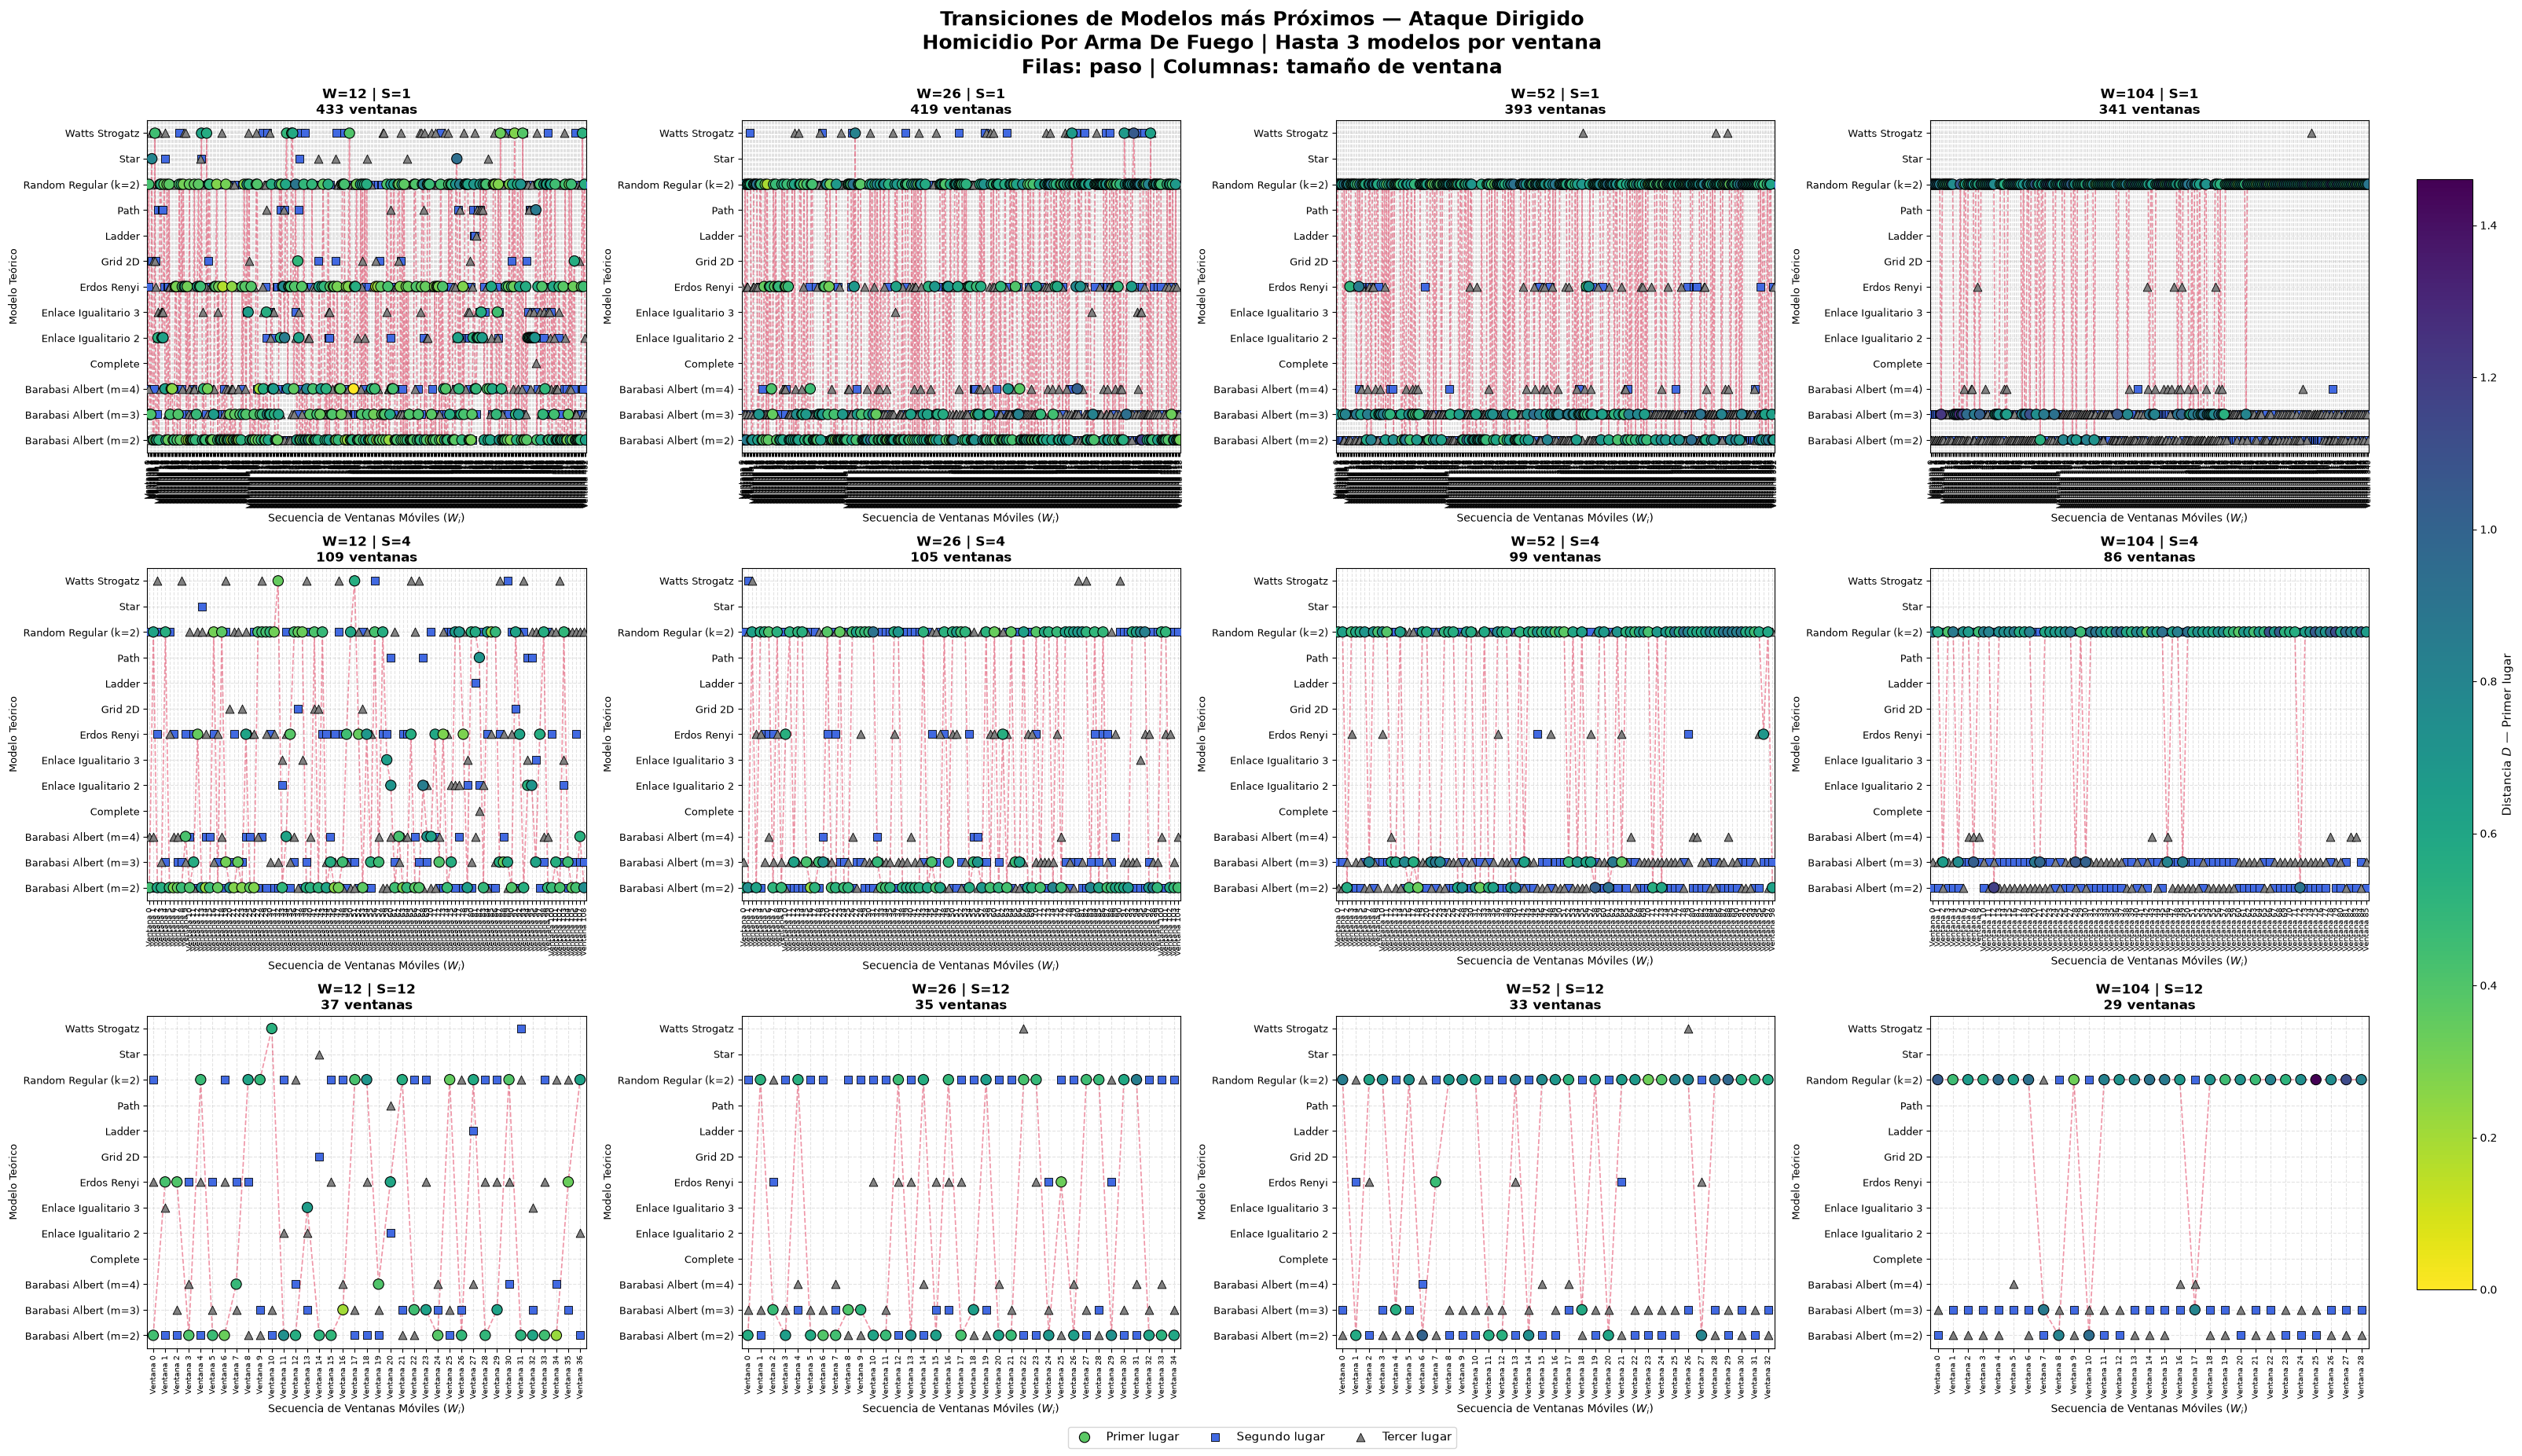

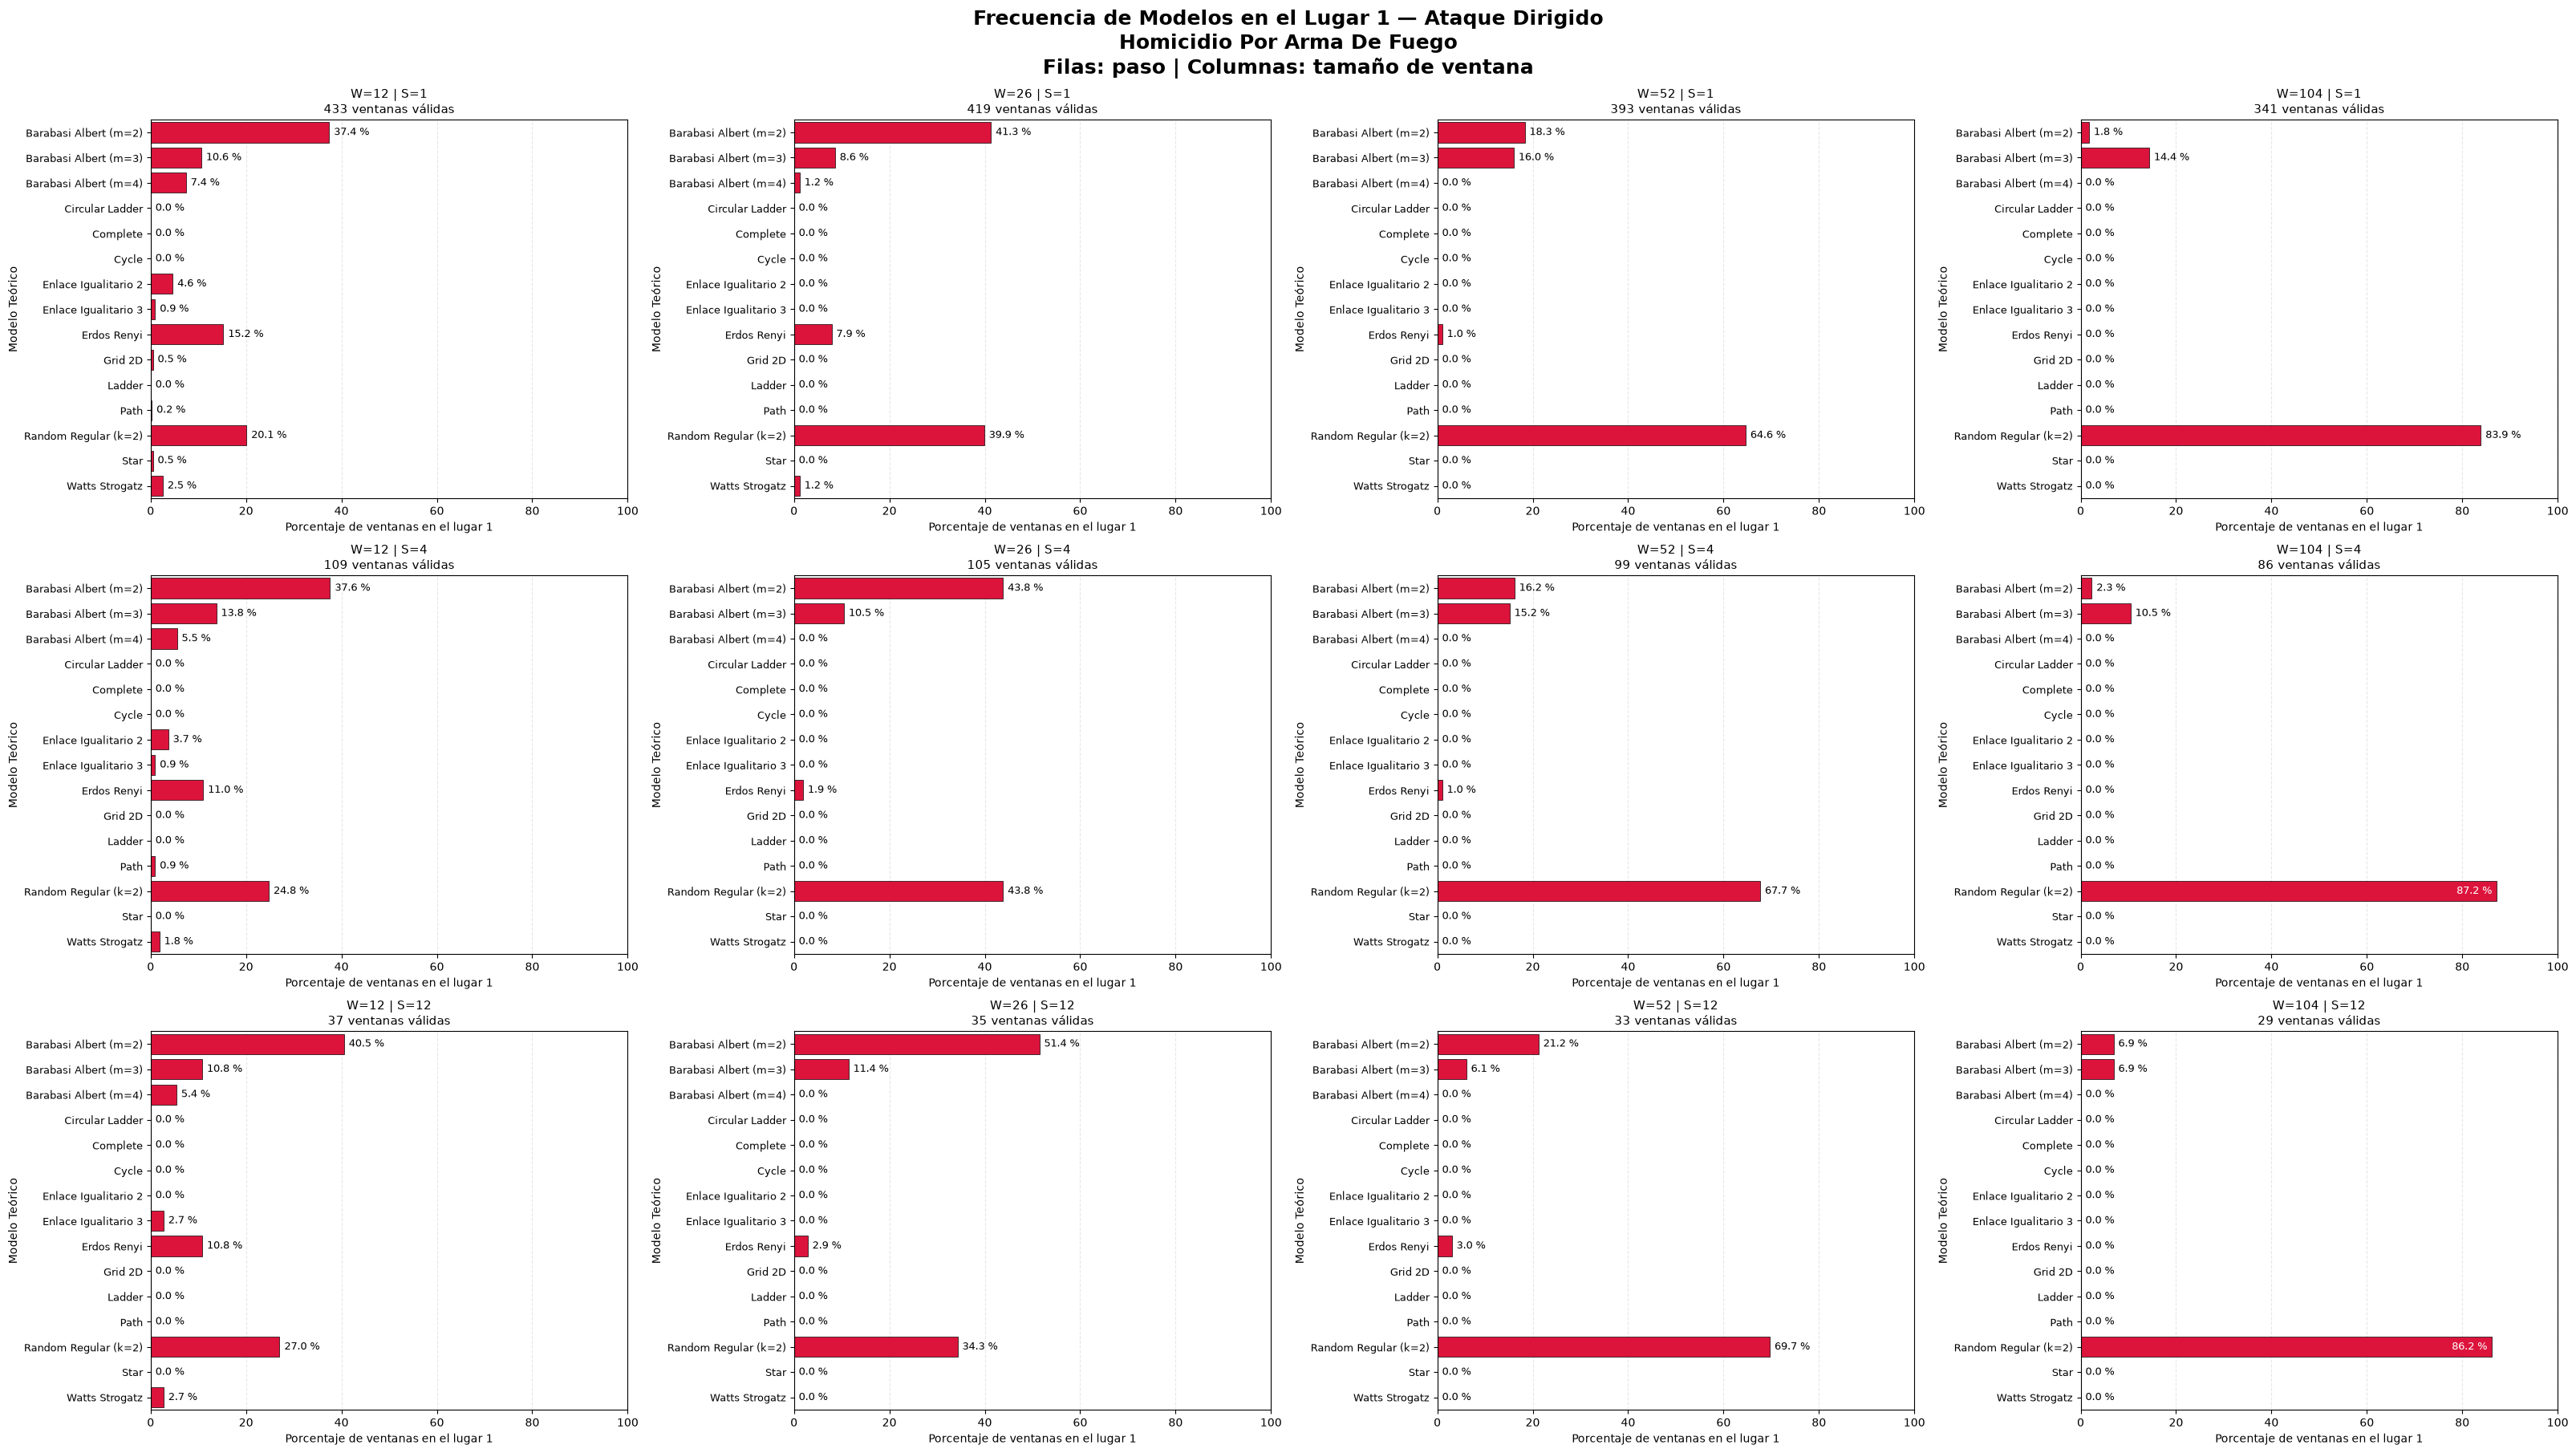

In [7]:
# SAVE GENERAL HISTOGRAM
fig = plots.plot_histogram(node_metrics)
fig.write_image( reports_folder_path / "histograma_general.png", width=1600, height=900, scale=3)
fig.write_image( reports_folder_path / "histograma_general.pdf", width=1600, height=900)

# Rolling Experiments
# PLOT RESILIENCE TRANSITIONS GRID
fig = plots.plot_resilience_transitions_grid(experimentos, strategy="attack", top_n=3)
fig.savefig(reports_folder_path / "transiciones_ataque_top3.png", dpi=300, bbox_inches="tight")
fig.savefig(reports_folder_path / "transiciones_ataque_top3.pdf", bbox_inches="tight")

strategy = "attack"
rank = 1
# SAVE PLOT RESILIENCE FREQUENCY GRID
fig = plots.plot_resilience_winner_frequency_grid(experimentos, strategy=strategy, rank=rank)
nombre = f"frecuencias_{strategy}_lugar{rank}_grid"
fig.savefig(reports_folder_path / f"{nombre}.png", dpi=300, bbox_inches="tight")
fig.savefig(reports_folder_path / f"{nombre}.pdf", bbox_inches="tight")



## <span style="color: white;">Load General From File</span>

#### Selector

In [15]:
series_nodes_selector = widgets.select_series_nodes(series_nodes_path)

Dropdown(description='Serie:', layout=Layout(width='100%'), options=(('HOMICIDIO POR ARMA DE FUEGO_SERIES_NODE…

In [16]:
print(series_nodes_selector.value)
# CARGA LOS NODOS DE LA SERIE
series_nodes = data_setup.load_series_nodes(series_nodes_selector.value)

# GENERA EL GRAFO DE VISIBILIDAD GENERAL
general_visibility_graph = graph.build_nvg(series_nodes, messages=False)
# CALCULA LAS METRICAS DEL GRAFO GENERAL
node_metrics = metrics.compute_node_metrics(g=general_visibility_graph)

c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\data\reports\HOMICIDIO POR ARMA DE FUEGO\series_nodes\HOMICIDIO POR ARMA DE FUEGO_SERIES_NODES_52851ccf565b4d1aab322ff9c446b8e4.pkl
2026-11-16 23:11:41,031 - [load_series_nodes] - INFO - EXITO ✅. Serie cargada desde: C:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\data\reports\HOMICIDIO POR ARMA DE FUEGO\series_nodes\HOMICIDIO POR ARMA DE FUEGO_SERIES_NODES_52851ccf565b4d1aab322ff9c446b8e4.pkl
2026-11-16 23:11:41,089 - [compute_node_metrics] - INFO - Calculando métricas y centralidades por nodo
2026-11-16 23:11:41,707 - [compute_node_metrics] - INFO - EXITO ✅. Métricas generadas para 444 nodos.


## <span style="color: white;">Working With Resilience Experiments</span>

### <span style="color: #FFFF00;">Select Working Experiment</span>

In [17]:
selector_reporte = widgets.select_report(report_path=reports_folder_path)

Dropdown(description='Reporte:', layout=Layout(width='100%'), options=(('HOMICIDIO POR ARMA DE FUEGO_W104_S12_…

In [18]:
rolling_report_name = selector_reporte.value
print(rolling_report_name)
rolling_experiment = data_setup.load_rolling_experiment(rolling_report_name)

c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\data\reports\HOMICIDIO POR ARMA DE FUEGO\HOMICIDIO POR ARMA DE FUEGO_W52_S1_c572ba50ec9f4e4ab7df21776b605839.pkl
2026-11-16 23:12:41,213 - [load_rolling_experiment] - INFO - EXITO ✅. Experimento cargado: HOMICIDIO POR ARMA DE FUEGO_W52_S1_c572ba50ec9f4e4ab7df21776b605839.pkl


### <span style="color: #FFFF00;">Resilience Plots</span>

#### Winners in Time

2026-11-16 23:12:48,704 - [plot_resilience_transitions] - INFO - Preparando transiciones de modelos de resiliencia
2026-11-16 23:12:49,033 - [plot_resilience_transitions] - INFO - EXITO ✅.


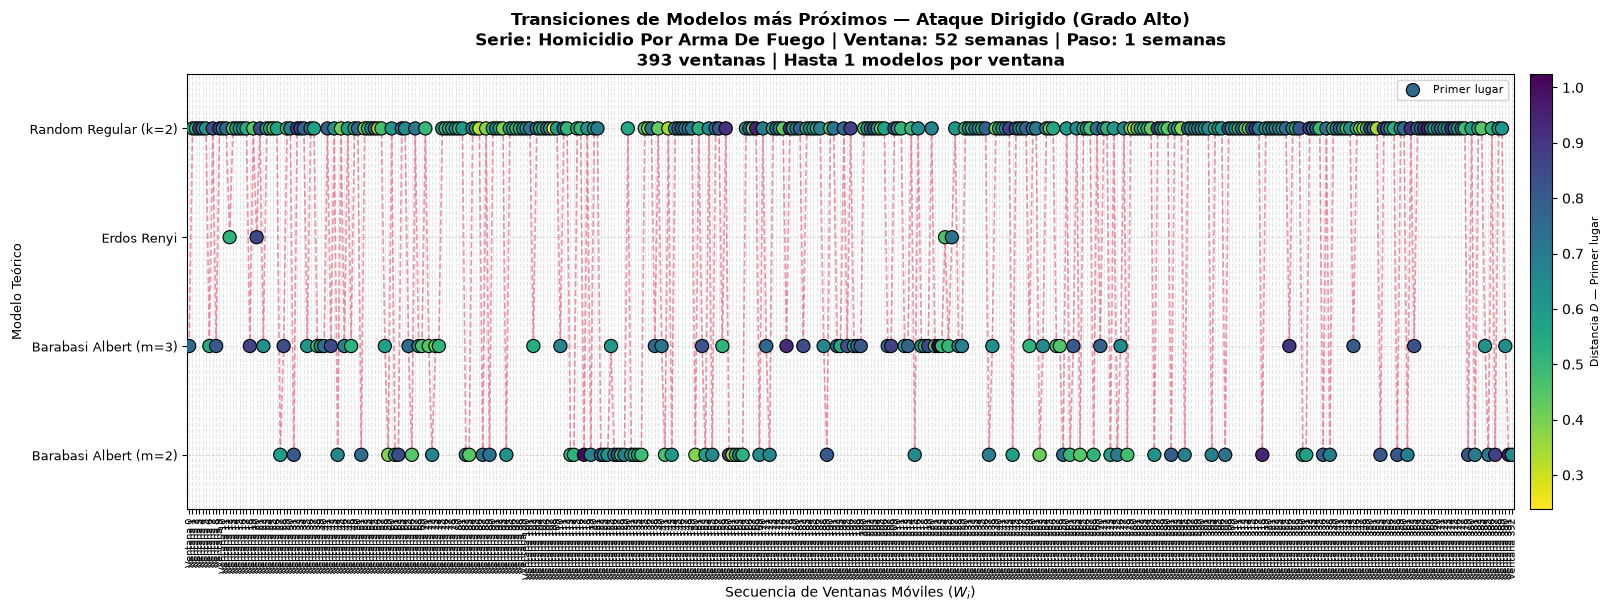

In [19]:
fig = plots.plot_resilience_transitions(rolling_experiment["rolling_resilience_results"], strategy="attack", top_n=1)

#### Winners Frequency

2026-11-16 23:13:23,415 - [plot_resilience_winner_frequency] - INFO - Preparando frecuencias del lugar 1 para la estrategia 'attack'.
2026-11-16 23:13:23,447 - [plot_resilience_winner_frequency] - INFO - EXITO ✅. Frecuencias calculadas sobre 393 ventanas válidas.


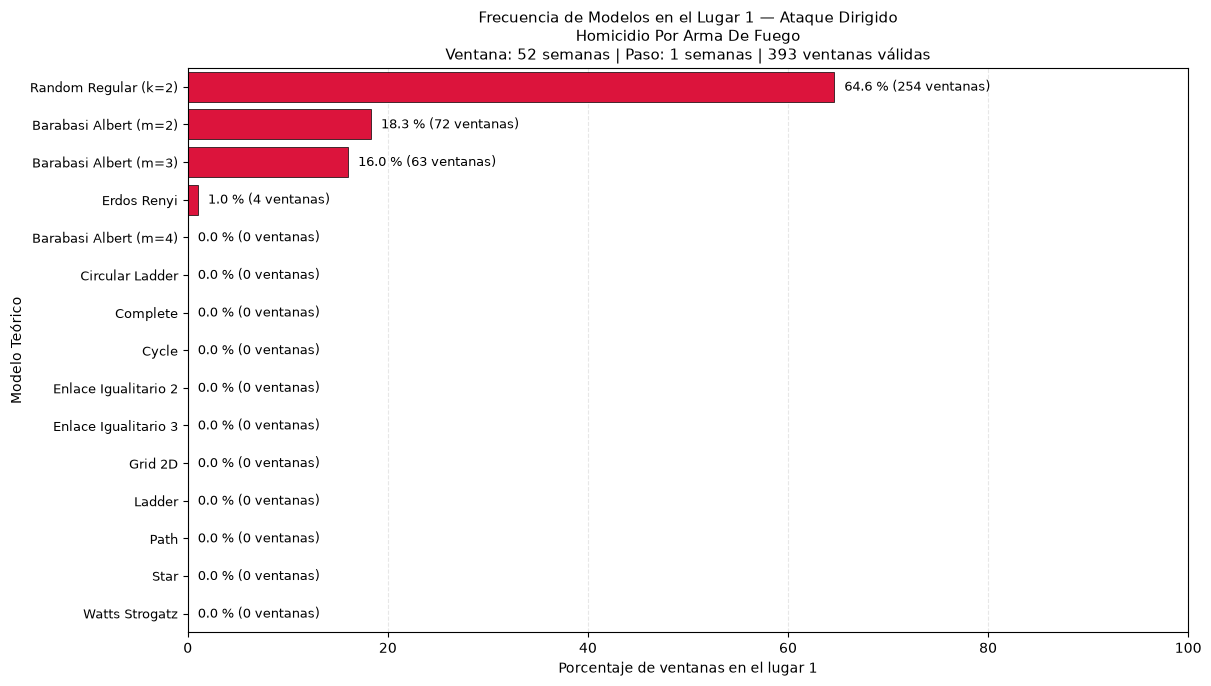

In [20]:
fig = plots.plot_resilience_winner_frequency(rolling_experiment["rolling_resilience_results"], strategy="attack", rank=1)

#### Histogram + Resilience

In [21]:
selector_histograma = widgets.select_histogram_resilience_options()

In [22]:
strategy = selector_histograma["strategy"].value
posicion = selector_histograma["rank"].value
modelos = list(selector_histograma["models"].value)
print(strategy, posicion, modelos)

rolling_resilience_rankings = reports.extract_rolling_resilience_rankings(experiment=rolling_experiment)
resilience_graph = reports.merge_resilience_graph(node_metrics=node_metrics, rolling_resilience_rankings=rolling_resilience_rankings)

fig = plots.plot_histogram_resilience(resilience_graph=resilience_graph, strategy=strategy, rank=posicion, models=modelos)
fig.show()

attack 1 ['Barabasi Albert (m=2)', 'Barabasi Albert (m=3)', 'Barabasi Albert (m=4)']
2026-11-16 23:13:42,216 - [plot_histogram] - INFO - Preparando visualización de conteos semanales
2026-11-16 23:13:42,242 - [plot_histogram] - INFO - EXITO ✅.
2026-11-16 23:13:42,316 - [plot_histogram_resilience] - WARNING - No hay puntos para 'Barabasi Albert (m=4)', estrategia='attack', posición=1.
2026-11-16 23:13:42,326 - [plot_histogram_resilience] - INFO - EXITO ✅. Histograma preparado con 135 marcas de resiliencia.


## <span style="color: white;">Working with A Graph</span>

### <span style="color: #FFFF00;">Widget Select Global Graph</span>

In [23]:
working_graph = general_visibility_graph

### <span style="color: #FFFF00;">Compute Metrics</span>

In [24]:
working_metrics = metrics.compute_node_metrics(g=working_graph)
graph_metrics = metrics.compute_graph_metrics(g=working_graph)
distribution_metrics = distributions.compute_distribution_metrics(graph_metrics=graph_metrics)
resilience_results = resilience.resilience_analysis(g=working_graph, seed=42)

2026-11-16 23:14:17,337 - [compute_node_metrics] - INFO - Calculando métricas y centralidades por nodo
2026-11-16 23:14:17,921 - [compute_node_metrics] - INFO - EXITO ✅. Métricas generadas para 444 nodos.
2026-11-16 23:14:17,924 - [compute_graph_metrics] - INFO - Calculando métricas globales del grafo
2026-11-16 23:14:18,403 - [compute_graph_metrics] - INFO - EXITO ✅.
2026-11-16 23:14:18,405 - [compute_distribution_metrics] - INFO - Calculando distribuciones y métricas de sus ajustes
2026-11-16 23:14:18,464 - [compute_distribution_metrics] - INFO - EXITO ✅. Distribuciones y comparaciones calculadas.
2026-11-16 23:14:18,465 - [resilience_analysis] - INFO - Iniciando análisis comparado de resiliencia
2026-11-16 23:14:20,278 - [resilience_analysis] - INFO - EXITO ✅. Resiliencia calculada para 'HOMICIDIO POR ARMA DE FUEGO': red empírica y 15 modelos teóricos.


### <span style="color: #FFFF00;">Legacy Plots</span>

#### Histogram

In [25]:
# plot_histogram
fig = plots.plot_histogram(node_metrics=working_metrics)
fig.show()

2026-11-16 23:14:29,456 - [plot_histogram] - INFO - Preparando visualización de conteos semanales
2026-11-16 23:14:29,484 - [plot_histogram] - INFO - EXITO ✅.


#### Visibility Graph

In [26]:
# plot_visibility_graph_from_network
fig = plots.plot_visibility_graph_from_network(g=working_graph)
fig.show()

2026-11-16 23:14:36,516 - [plot_visibility_graph_from_network] - INFO - Preparando visualización del grafo de visibilidad
2026-11-16 23:14:36,617 - [plot_visibility_graph_from_network] - INFO - EXITO ✅.


#### Network

2026-11-16 23:14:46,128 - [plot_network] - INFO - Preparando visualización de la red


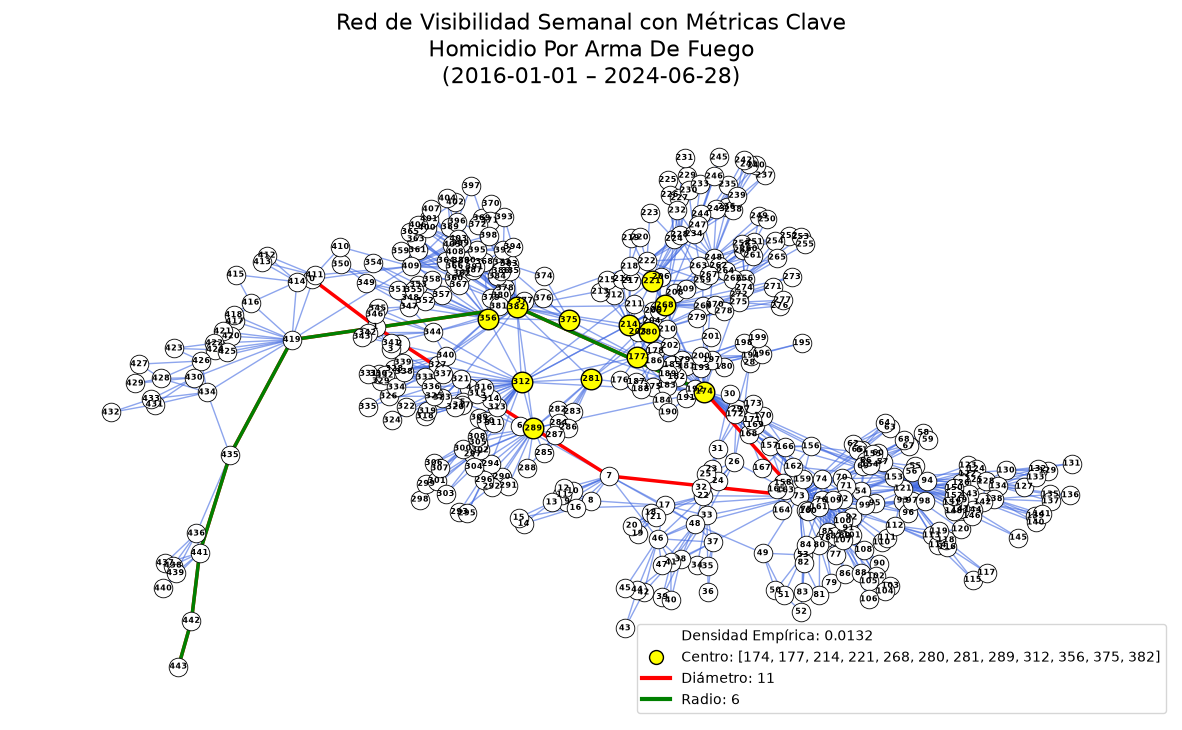

2026-11-16 23:14:47,835 - [plot_network] - INFO - Exito.


In [27]:
# plot_network
plots.plot_network(g=general_visibility_graph, metrics=graph_metrics)

#### Distributions

##### <span style="color: #D35400;">Degree distribution Probability</span>

2026-11-16 23:15:00,757 - [plot_degree_distribution] - INFO - Preparando distribución empírica de grados
2026-11-16 23:15:00,781 - [plot_degree_distribution] - INFO - EXITO ✅. Distribución empírica de grados graficada.


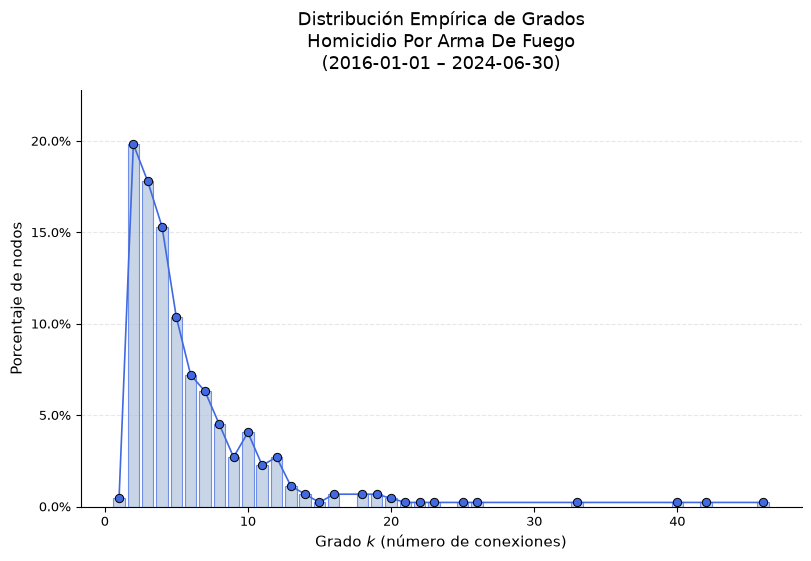

In [28]:
plots.plot_degree_distribution(distribution_metrics, start_date=config.START_DATE, end_date=config.END_DATE)

##### <span style="color: #D35400;">Degree distribution sorted</span>

2026-11-16 23:15:09,366 - [plot_degree_distribution_sorted] - INFO - Preparando gráfico de distribución de grados


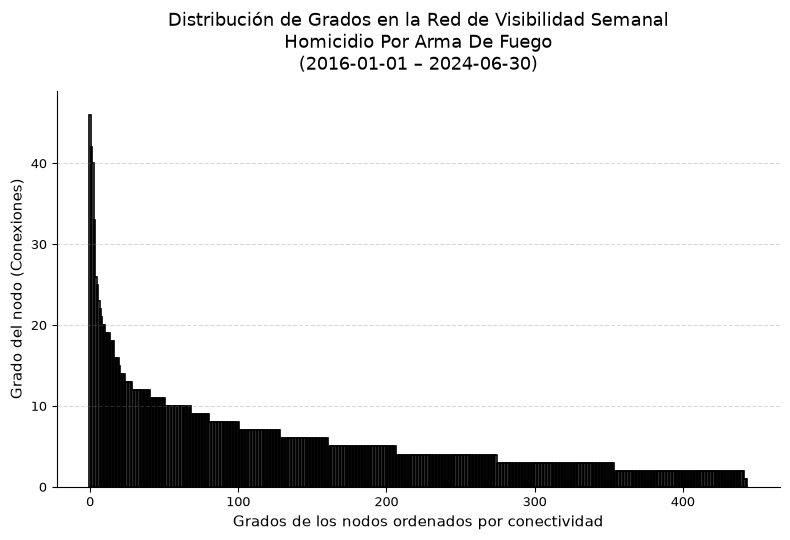

2026-11-16 23:15:09,949 - [plot_degree_distribution_sorted] - INFO - Exito.


In [29]:
# plot_degree_distribution
plots.plot_degree_distribution_sorted(graph_metrics=graph_metrics, start_date=config.START_DATE, end_date=config.END_DATE)

##### <span style="color: #D35400;">Power Law Fit</span>

2026-11-16 23:15:18,171 - [plot_power_law_fit] - INFO - Iniciando visualización del ajuste de Ley de Potencia


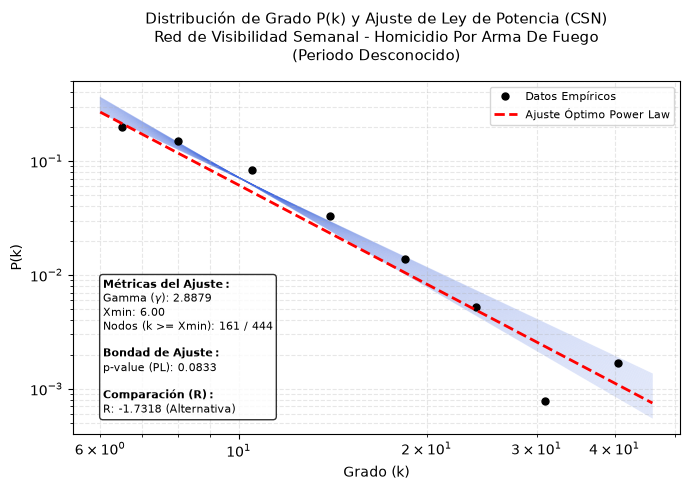

2026-11-16 23:15:18,591 - [plot_power_law_fit] - INFO - Exito.


In [30]:
# plot_power_law_fit
plots.plot_power_law_fit(distribution_metrics=distribution_metrics)

##### <span style="color: #D35400;">Model Comparison</span>

2026-11-16 23:15:26,693 - [plot_model_comparison] - INFO - Iniciando visualización de comparación multimodelo


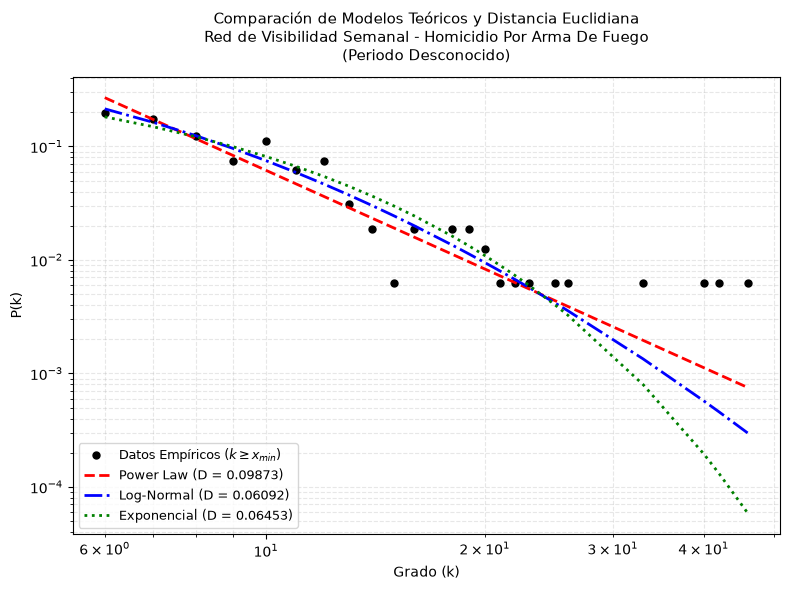

2026-11-16 23:15:27,096 - [plot_model_comparison] - INFO - EXITO.


In [31]:
# plot_model_comparison
plots.plot_model_comparison(distribution_metrics=distribution_metrics)

##### <span style="color: #D35400;">CSN Analysis</span>

2026-11-16 23:15:37,667 - [plot_csn_analysis] - INFO - Iniciando visualización del análisis CSN


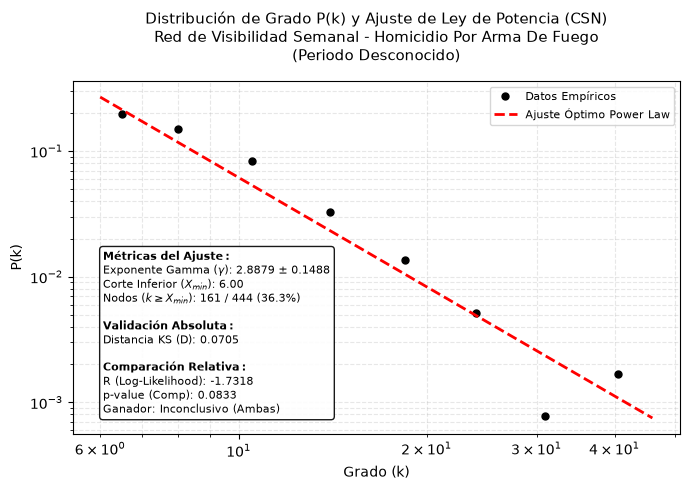

2026-11-16 23:15:38,134 - [plot_csn_analysis] - INFO - EXITO.


In [32]:
# plot_csn_analysis
plots.plot_csn_analysis(distribution_metrics=distribution_metrics)

##### <span style="color: #D35400;">Distances</span>

In [ ]:
# print_distribution_distances
reports.print_distribution_distances(distribution_metrics)

##### <span style="color: #D35400;">Resilience</span>

2026-11-16 23:15:43,823 - [plot_closest_resilience_models] - INFO - Preparando contraste de modelos más cercanos


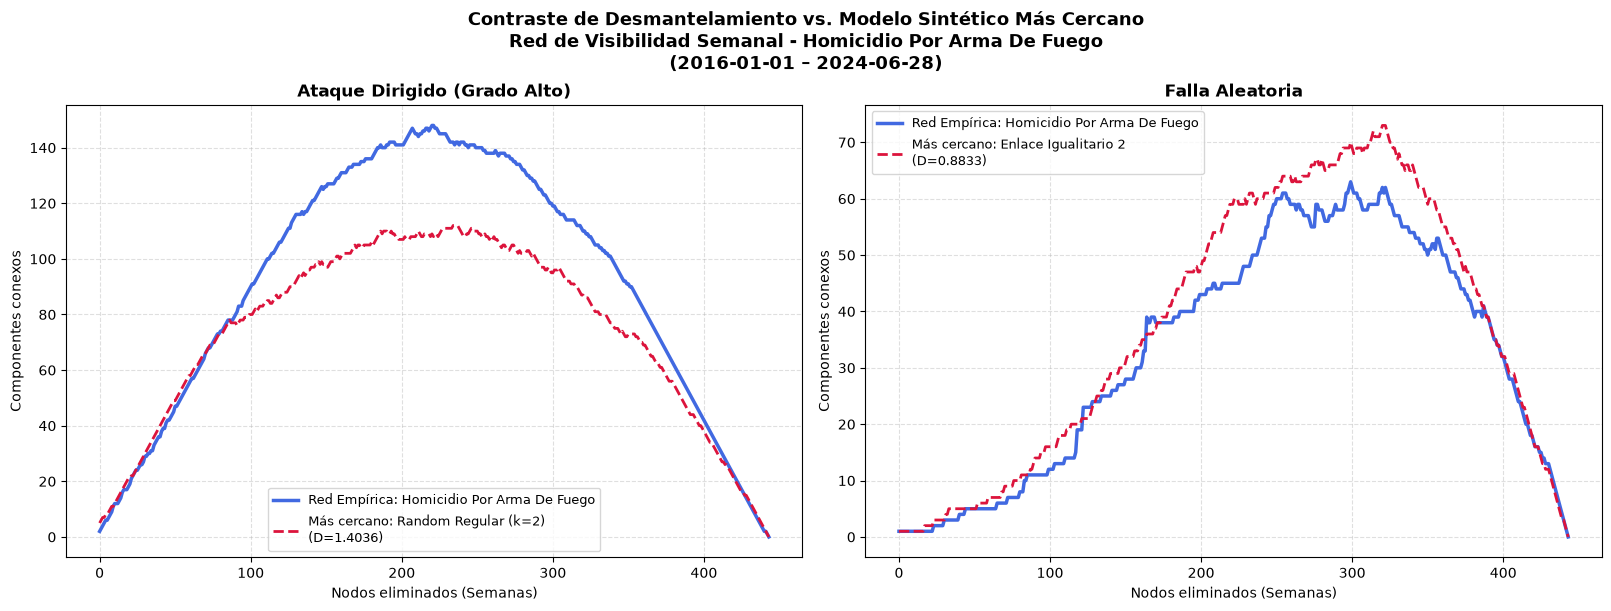

2026-11-16 23:15:44,204 - [plot_closest_resilience_models] - INFO - EXITO.


In [33]:
# plot_closest_resilience_models
plots.plot_closest_resilience_models(resilience_results=resilience_results)

##### <span style="color: #D35400;">Resilience Grid</span>

In [ ]:
# plot_resilience_grid
plots.plot_resilience_grid(resilience_results=resilience_results, strategy = "both")

## <span style="color: white;">Experiment 2 </span>

### <span style="color: #FFFF00;">Select Working Experiment</span>

#### Selector

In [34]:
selector_reporte = widgets.select_report(report_path=reports_folder_path)

Dropdown(description='Reporte:', layout=Layout(width='100%'), options=(('HOMICIDIO POR ARMA DE FUEGO_W104_S12_…

In [35]:
rolling_report_name = selector_reporte.value
print(rolling_report_name)
rolling_experiment = data_setup.load_rolling_experiment(rolling_report_name)
window_selector = widgets.select_window(rolling_experiment=rolling_experiment)


c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\data\reports\HOMICIDIO POR ARMA DE FUEGO\HOMICIDIO POR ARMA DE FUEGO_W52_S12_c804d4eff3d04d11a5a8f75587f5768a.pkl
2026-11-16 23:16:10,450 - [load_rolling_experiment] - INFO - EXITO ✅. Experimento cargado: HOMICIDIO POR ARMA DE FUEGO_W52_S12_c804d4eff3d04d11a5a8f75587f5768a.pkl


Dropdown(description='Ventana:', layout=Layout(width='420px'), options=(('Ventana 0 (2016-01-01 – 2016-12-23)'…

#### Load Variables

In [36]:
window_id = window_selector.value

# window_graph["grafo"]
window_graph = reports.get_graph_by_window(rolling_experiment, window_id=window_id)
# window_graph_metrics["graph_metrics"]
window_graph_metrics = reports.get_graph_metrics_by_window(rolling_experiment, window_id=window_id)
# window_distribution_metrics["distribution_metrics"]
window_distribution_metrics = reports.get_distribution_metrics_by_window(rolling_experiment, window_id=window_id)
# window_metrics_resilience["data"]
window_metrics_resilience = reports.extract_metrics_by_window(rolling_experiment)
# window_resilience_results["resilience_results"]
window_resilience_results = reports.get_resilience_results_by_window(rolling_experiment, windows_id=window_id)


2026-11-16 23:16:23,652 - [extract_metrics_by_window] - INFO - EXITO ✅. Datos relacionados: 33 ventanas y 990 comparaciones.


### <span style="color: #FFFF00;">Plots</span>

#### Histograma

In [38]:
plots.plot_visibility_graph_from_network(window_graph["graph"])

2026-11-16 23:16:36,819 - [plot_visibility_graph_from_network] - INFO - Preparando visualización del grafo de visibilidad
2026-11-16 23:16:36,841 - [plot_visibility_graph_from_network] - INFO - EXITO ✅.


#### Distribucion de grados ordenado

2026-11-16 23:16:51,693 - [plot_degree_distribution_sorted] - INFO - Preparando gráfico de distribución de grados


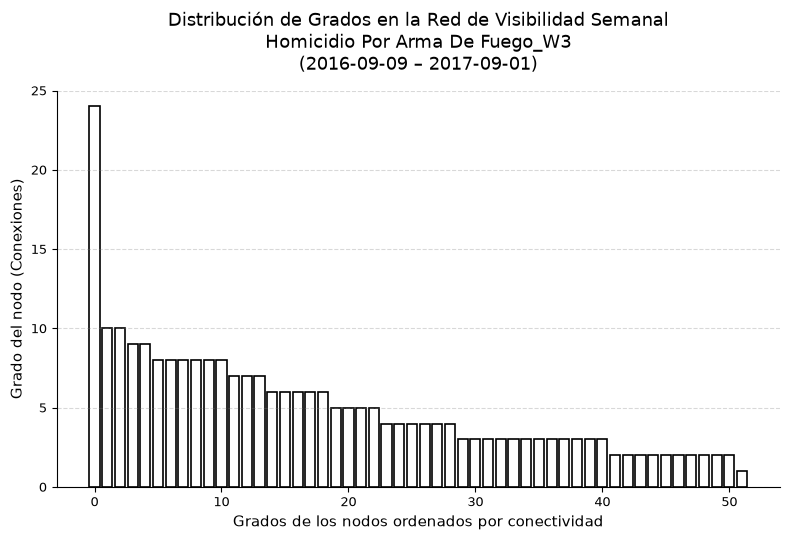

2026-11-16 23:16:51,877 - [plot_degree_distribution_sorted] - INFO - Exito.


In [39]:
plots.plot_degree_distribution_sorted(
    window_graph_metrics["graph_metrics"],
    start_date=window_graph_metrics["start_date"],
    end_date=window_graph_metrics["end_date"],
)

#### Distribucion de grados probabilidad

2026-11-16 23:16:57,128 - [plot_degree_distribution] - INFO - Preparando distribución empírica de grados
2026-11-16 23:16:57,154 - [plot_degree_distribution] - INFO - EXITO ✅. Distribución empírica de grados graficada.


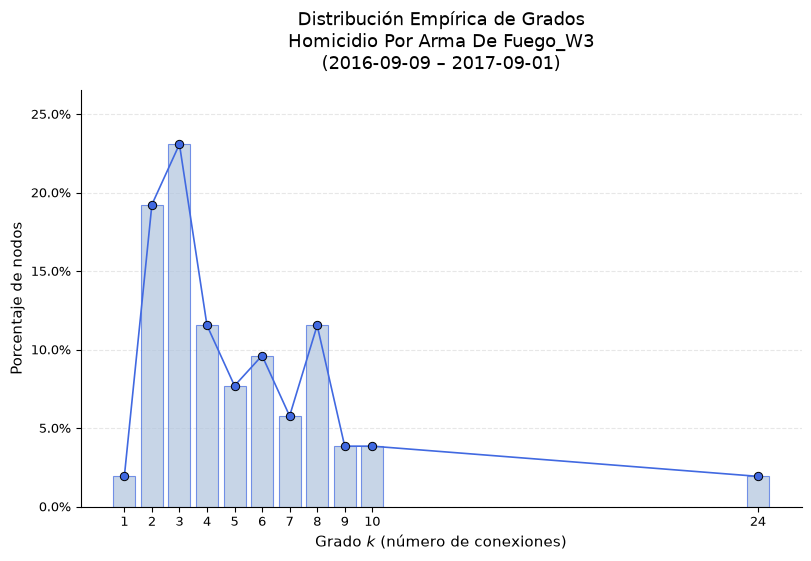

In [40]:
plots.plot_degree_distribution(
    distribution_metrics=window_distribution_metrics["distribution_metrics"],
    start_date=window_distribution_metrics["start_date"],
    end_date=window_distribution_metrics["end_date"],
)

#### Red

2026-11-16 23:17:01,915 - [plot_network] - INFO - Preparando visualización de la red


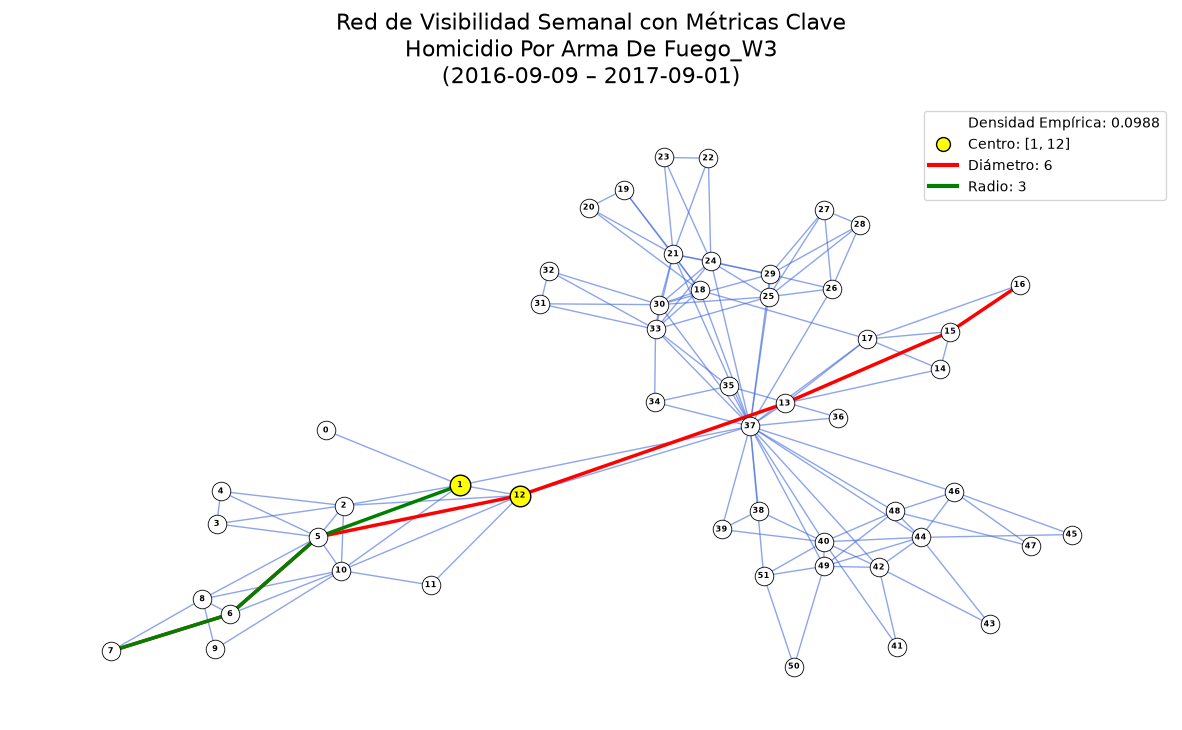

2026-11-16 23:17:02,157 - [plot_network] - INFO - Exito.


In [41]:

plots.plot_network(g=window_graph["graph"], metrics=window_graph_metrics["graph_metrics"])

#### Resiliencia

2026-11-16 23:17:07,429 - [plot_closest_resilience_models] - INFO - Preparando contraste de modelos más cercanos


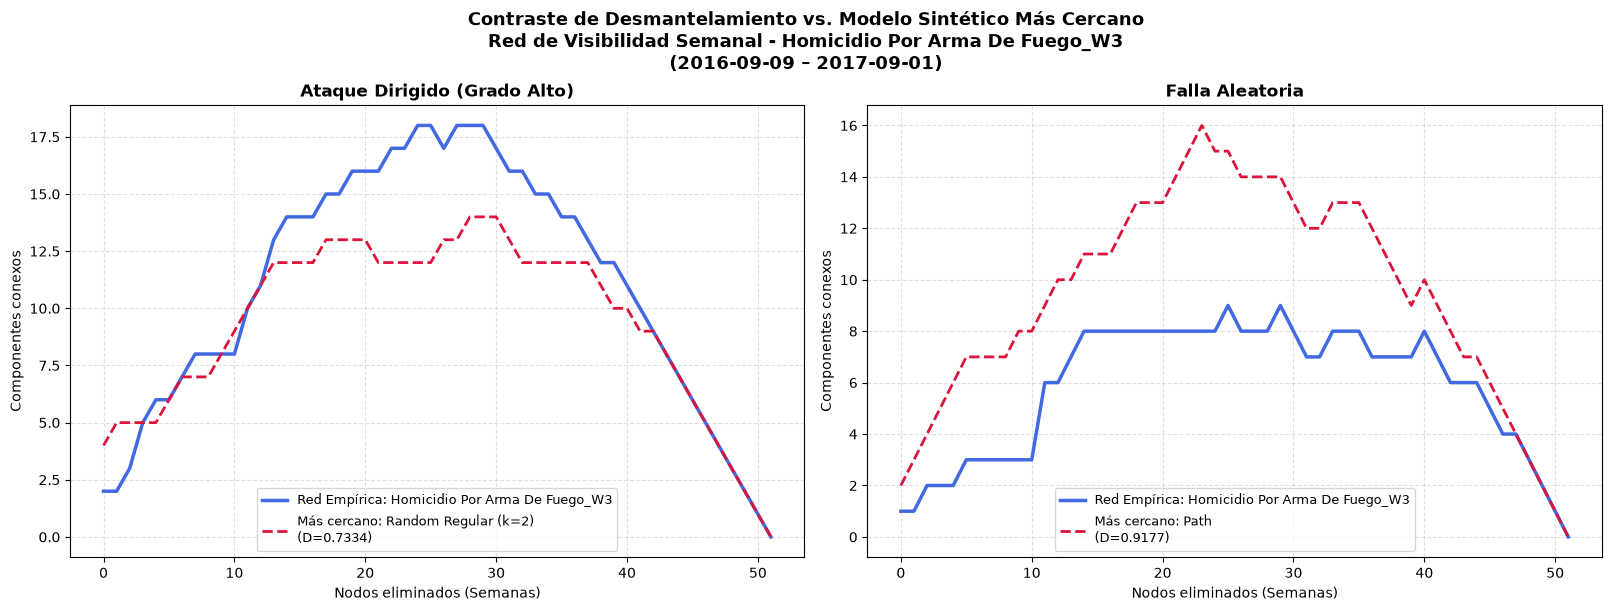

2026-11-16 23:17:07,841 - [plot_closest_resilience_models] - INFO - EXITO.


In [42]:
plots.plot_closest_resilience_models(window_resilience_results["resilience_results"])

#### Resilience Grid

2026-11-16 23:17:12,264 - [plot_resilience_grid] - INFO - Preparando cuadrícula de curvas de resiliencia


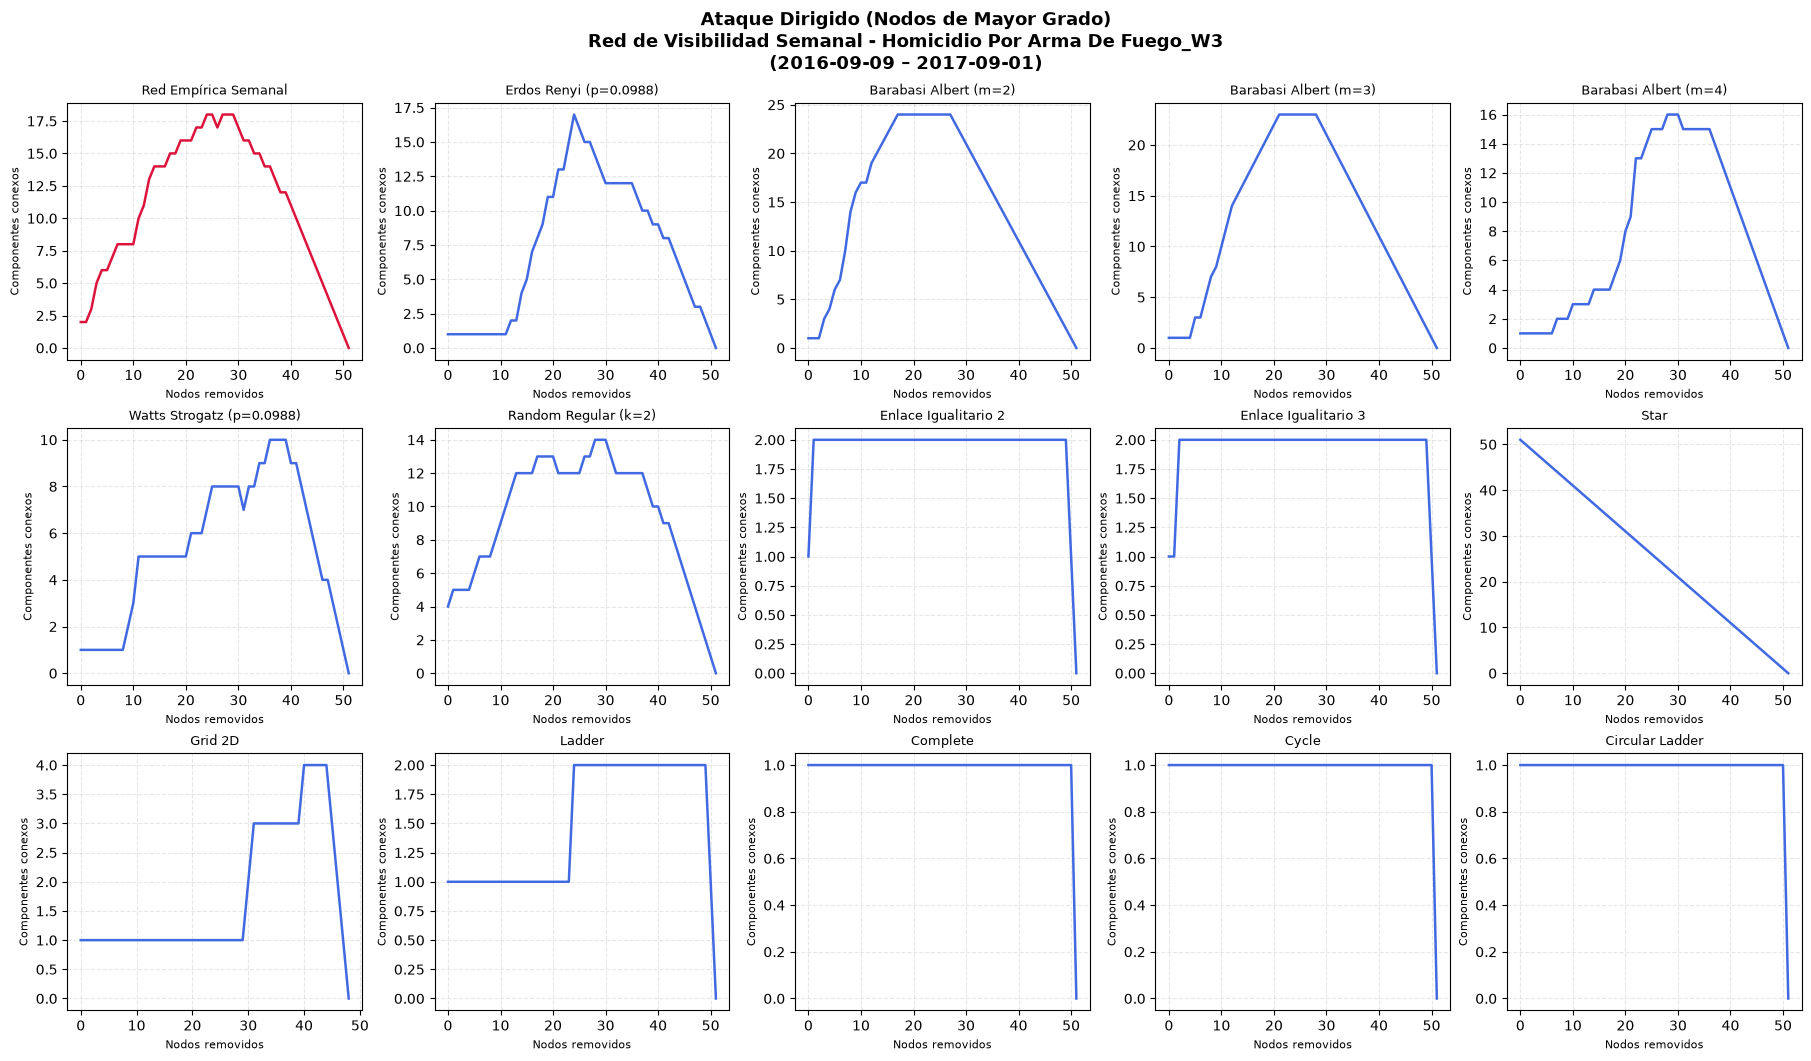

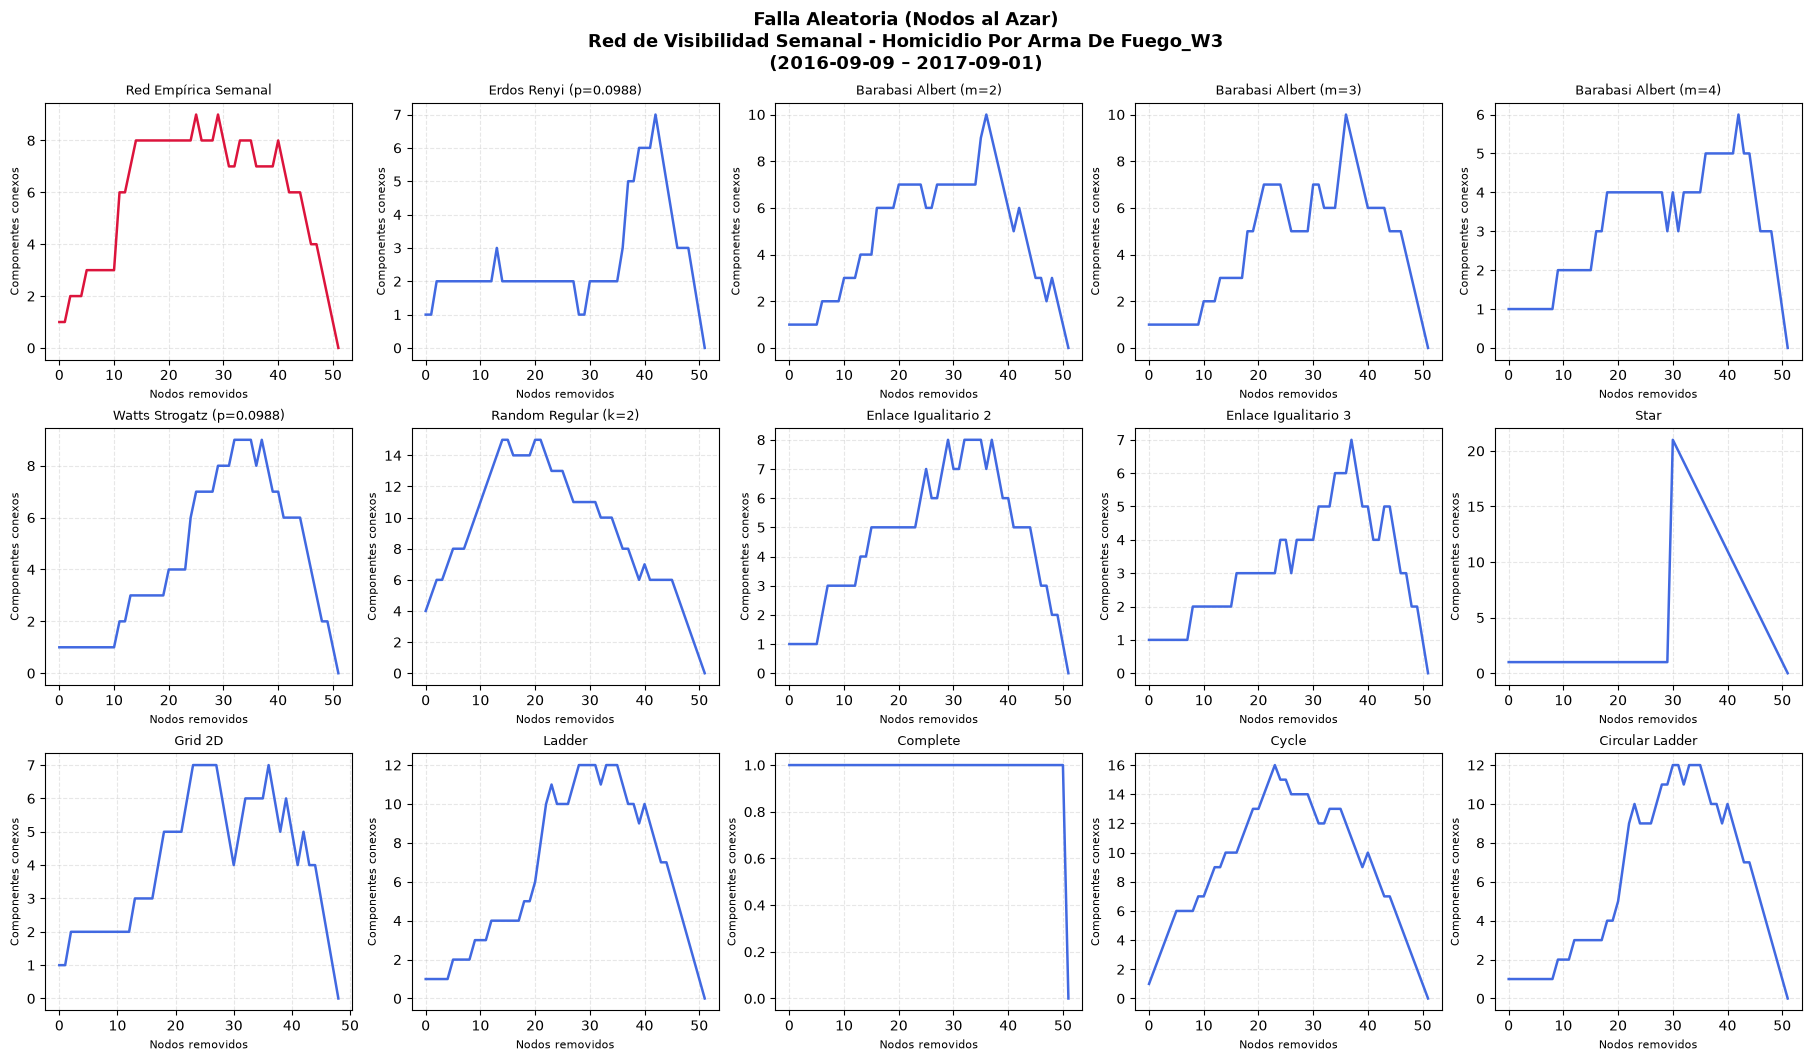

2026-11-16 23:17:15,858 - [plot_resilience_grid] - INFO - EXITO ✅.


In [43]:
plots.plot_resilience_grid(window_resilience_results["resilience_results"], strategy = "both" )

### <span style="color: #FFFF00;">Todos los indicadores.</span>

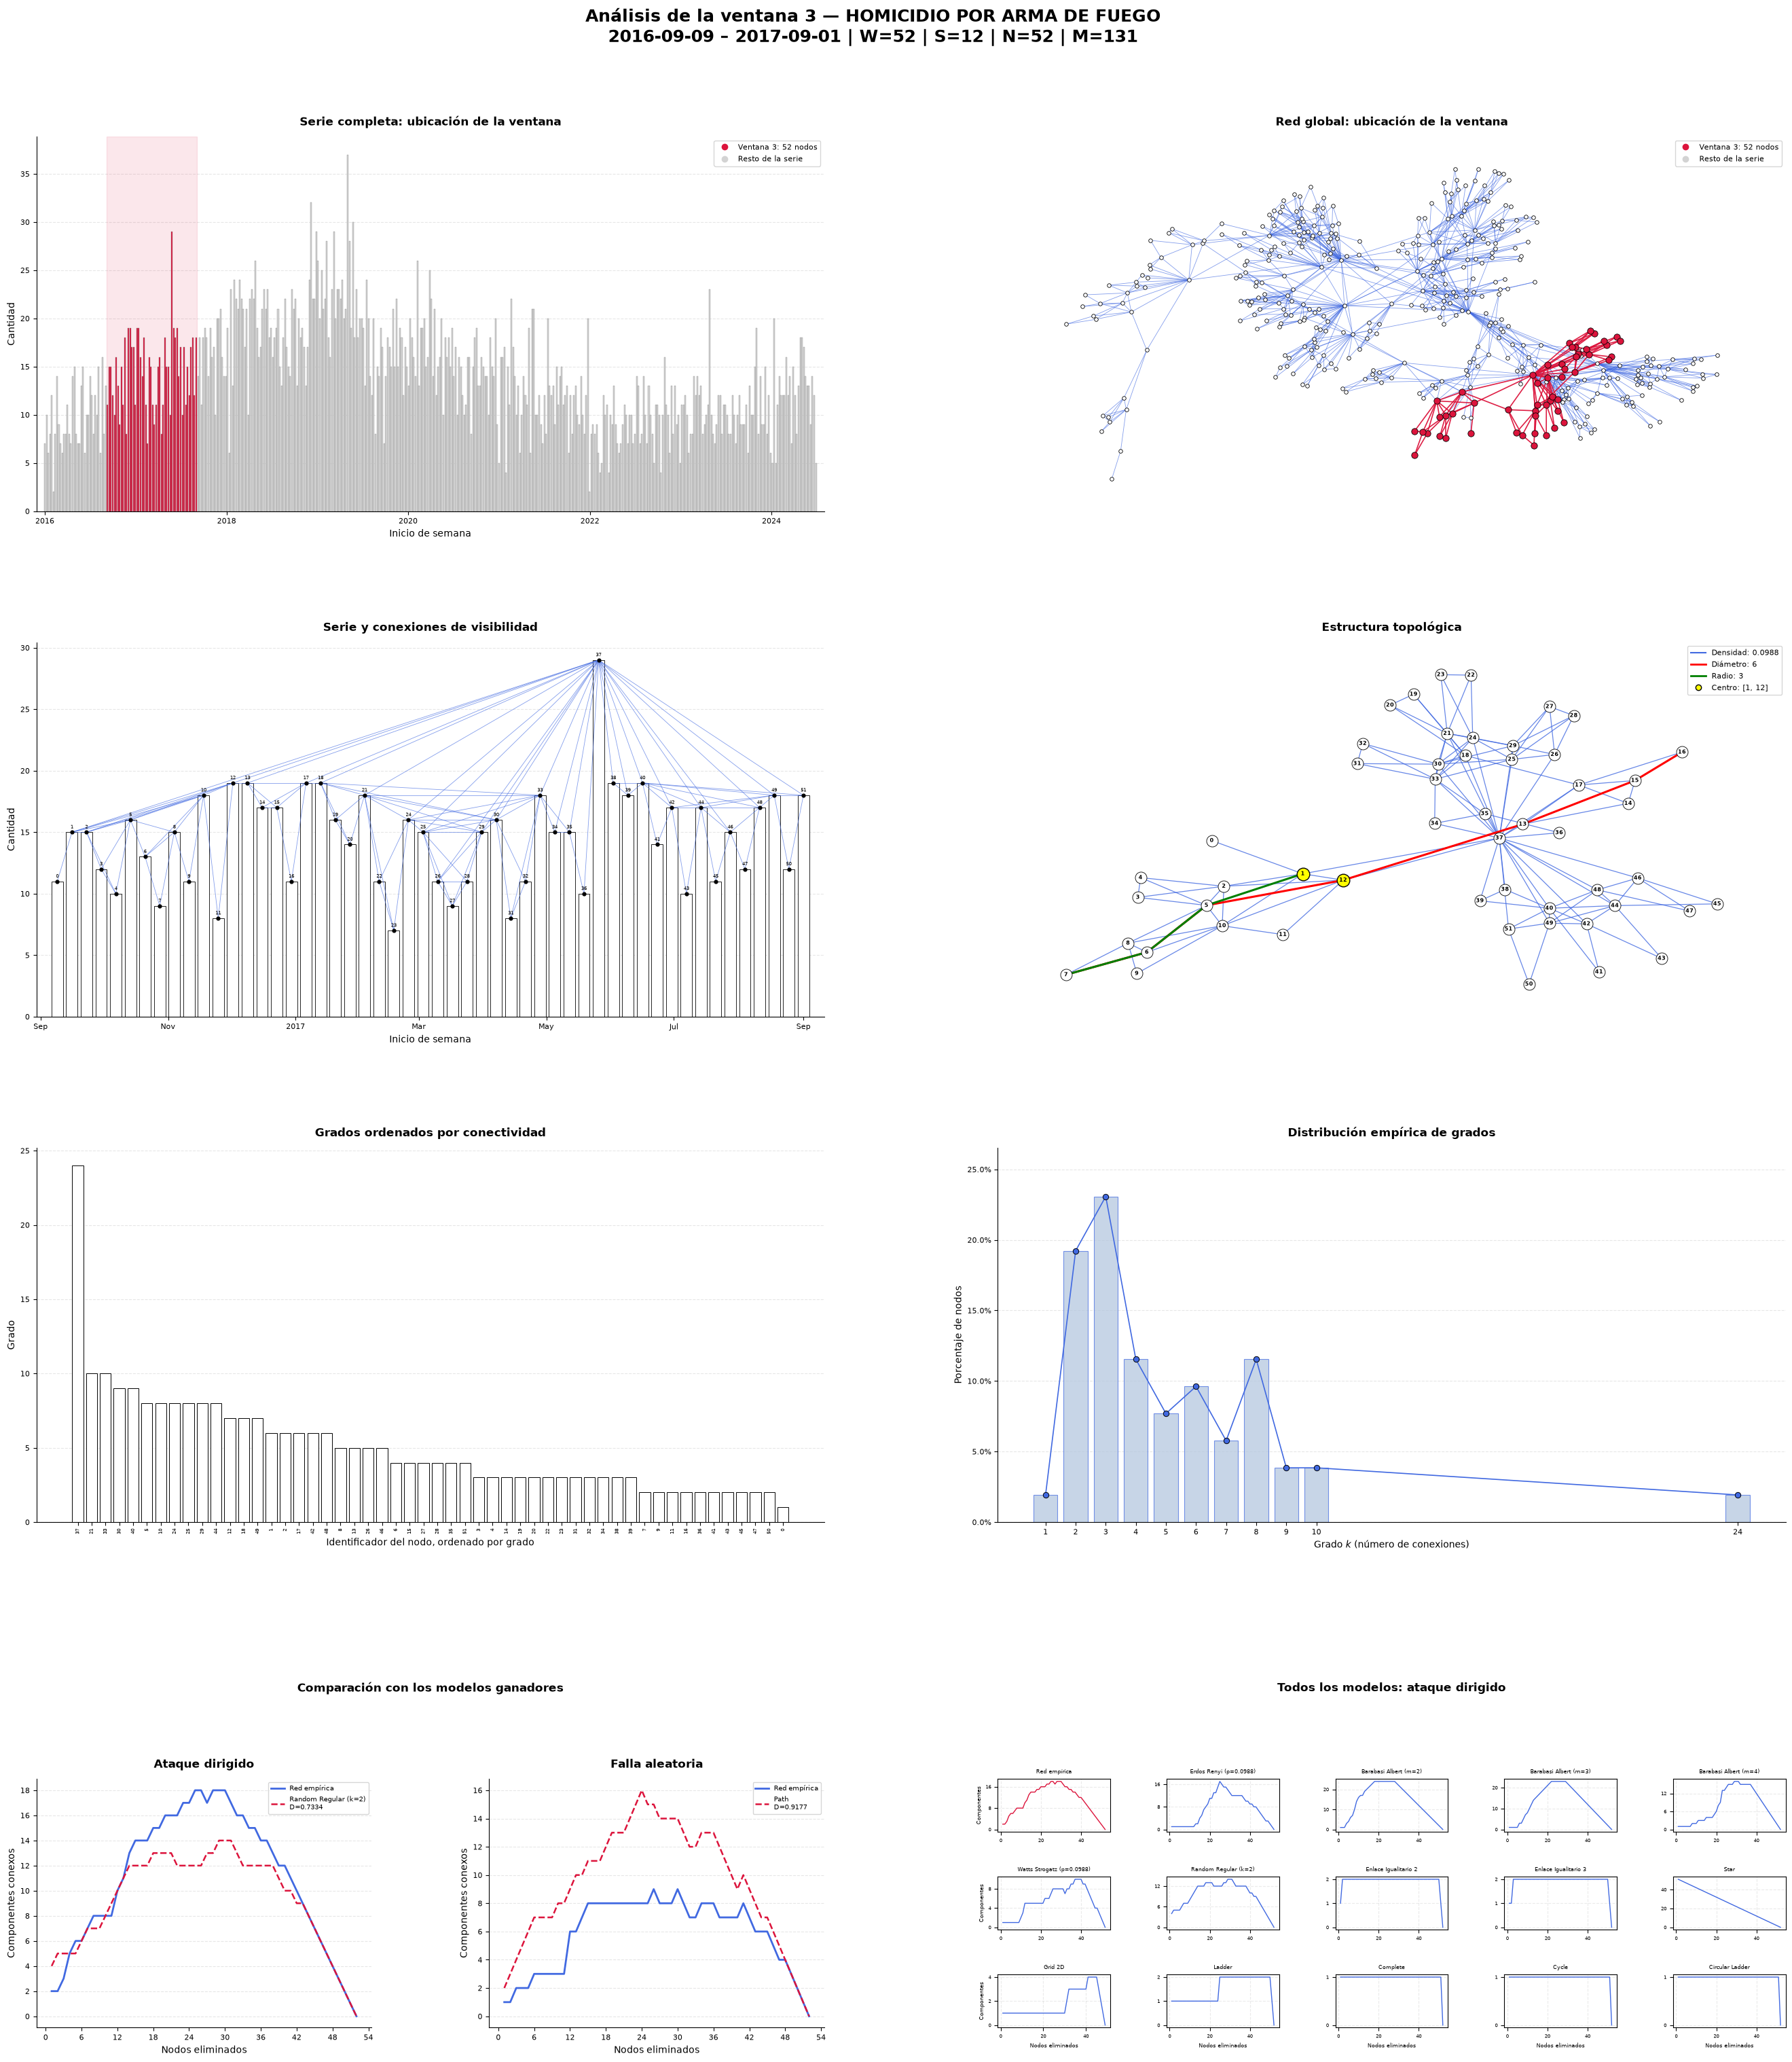

In [46]:
import os

window_graph = reports.get_graph_by_window(rolling_experiment, window_id=window_id)
fig = plots.plot_window_analysis(rolling_experiment, window_id=window_id, global_visibility_graph=general_visibility_graph, show_global_edges=True,)
display(fig)

nombre = "ventana_20_analisis"

fig.savefig(
    reports_folder_path / f"{nombre}.pdf",
    facecolor="white",
)

fig.savefig(
    reports_folder_path / f"{nombre}.png",
    dpi=300,
    facecolor="white",
)

ruta_imagen = reports_folder_path / "ventana_20_analisis.png"
#os.startfile(str(ruta_imagen.resolve()))

## <span style="color: white;">Experiment 3 </span>

In [47]:
simulacion = resilience.resilience_simulator(g=window_graph["graph"])
curva_registro = [estado["n_components"] for estado in simulacion["attack_log"][1:]]
curva_original = resilience.simulate_resilience_profile(window_graph["graph"], sorting_strategy="attack")
print("Coinciden:", curva_registro == curva_original.tolist())


2026-11-16 23:18:44,518 - [resilience_simulator] - INFO - Iniciando simulación de ataque por grado inicial
2026-11-16 23:18:44,522 - [resilience_simulator] - INFO - EXITO ✅. Ataque registrado: 52 eliminaciones y 53 estados.
Coinciden: True


In [48]:
simulacion = resilience.resilience_simulator(g=window_graph["graph"])

panel_simulacion = widgets.show_resilience_simulation(simulacion, interval=1000,)

2026-11-16 23:18:48,274 - [resilience_simulator] - INFO - Iniciando simulación de ataque por grado inicial
2026-11-16 23:18:48,277 - [resilience_simulator] - INFO - EXITO ✅. Ataque registrado: 52 eliminaciones y 53 estados.


## <span style="color: white;">DATASET CREATION </span>

### ESCALERA CLEAN

In [ ]:
df, serie_semanal = datasets.generar_dataset_escalera_clean()
fig, ax = plt.subplots(figsize=(13, 4))

ax.bar(
    serie_semanal["semana"],
    serie_semanal["frecuencia"],
    width=1,
    color="steelblue",
)

ax.set(
    title="Dataset sintético: escalera de frecuencias semanales",
    xlabel="Semana",
    ylabel="Número de registros",
    xlim=(0.5, len(serie_semanal) + 0.5),
    ylim=(0, 55),
)
ax.set_yticks([0, 25, 50])

plt.tight_layout()
plt.show()

### ESCALERA NOISE

In [ ]:
df, serie_semanal = datasets.generar_dataset_escalera_noise(
    nombre="escalera_5_25_50_25_5_ruido_2",
    ruido_max=2,
    seed=42,
)

fig, ax = plt.subplots(figsize=(13, 4))

ax.bar(
    serie_semanal["semana"],
    serie_semanal["frecuencia"],
    width=1,
    color="steelblue",
)

ax.set(
    title="Dataset sintético: escalera de frecuencias semanales",
    xlabel="Semana",
    ylabel="Número de registros",
    xlim=(0.5, len(serie_semanal) + 0.5),
    ylim=(0, 55),
)
ax.set_yticks([0, 25, 50])

plt.tight_layout()
plt.show()

### DATASET PERIODICO

In [ ]:
import matplotlib.pyplot as plt
df_periodico, serie_periodica = datasets.generar_dataset_periodico_clear(nombre="periodico_5_ciclos", ciclos=5,)

# df_periodico, serie_periodica = generar_dataset_periodico(nombre="periodico_periodo_20", periodo=20,)

fig, ax = plt.subplots(figsize=(15, 4))

ax.plot(
    serie_periodica["fecha_inicio_semana"],
    serie_periodica["frecuencia"],
    color="royalblue",
    linewidth=1.8,
)

# Límites entre las tres secciones.
for posicion in [148, 296]:
    ax.axvline(
        serie_periodica["fecha_inicio_semana"].iloc[posicion],
        color="crimson",
        linestyle="--",
        alpha=0.7,
    )

ax.set(
    title="Dos ciclos de 1–25, dos ciclos de 1–50 y nivel estable en 50",
    xlabel="Fecha",
    ylabel="Frecuencia semanal",
    ylim=(0, 55),
)

ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### DATASET PERIODICO NOISE

In [ ]:
df, serie_semanal = datasets.generar_dataset_periodico_noise(
    nombre="periodico_5_ciclos_ruido_2",
    ciclos=5,
    ruido_max=4,
    seed=42,
)

# df, serie_semanal = datasets.generar_dataset_periodico_noise(
#     nombre="periodico_periodo_20_ruido_2",
#     periodo=20,
#     ruido_max=2,
#     seed=42,
# )

fig, ax = plt.subplots(figsize=(15, 4))

ax.plot(
    serie_semanal["fecha_inicio_semana"],
    serie_semanal["frecuencia"],
    color="royalblue",
    linewidth=1.8,
)

# Límites entre las tres secciones.
for posicion in [148, 296]:
    ax.axvline(
        serie_semanal["fecha_inicio_semana"].iloc[posicion],
        color="crimson",
        linestyle="--",
        alpha=0.7,
    )

ax.set(
    title="Serie periódica con ruido: máximos base de 25 y 50, y nivel base de 50",
    xlabel="Fecha",
    ylabel="Frecuencia semanal",
)

ax.set_ylim(bottom=0)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()